# Amazon Sales Analysis: Do Discounts Actually Pay Off?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("amazon_sales_dataset.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (50000, 13)


,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue
0,1,2022-04-13,2637,Books,128.75,10,4,North America,UPI,3.5,443,115.88,463.52
1,2,2023-03-12,2300,Fashion,302.60,20,5,Asia,Credit Card,3.7,475,242.08,1210.40
2,3,2022-09-28,3670,Sports,495.80,20,2,Europe,UPI,4.4,183,396.64,793.28
3,4,2022-04-17,2522,Books,371.95,15,4,Middle East,UPI,5.0,212,316.16,1264.64
4,5,2022-03-13,1717,Beauty,201.68,0,4,Middle East,UPI,4.6,308,201.68,806.72


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          50000 non-null  int64  
 1   order_date        50000 non-null  str    
 2   product_id        50000 non-null  int64  
 3   product_category  50000 non-null  str    
 4   price             50000 non-null  float64
 5   discount_percent  50000 non-null  int64  
 6   quantity_sold     50000 non-null  int64  
 7   customer_region   50000 non-null  str    
 8   payment_method    50000 non-null  str    
 9   rating            50000 non-null  float64
 10  review_count      50000 non-null  int64  
 11  discounted_price  50000 non-null  float64
 12  total_revenue     50000 non-null  float64
dtypes: float64(4), int64(5), str(4)
memory usage: 5.0 MB


In [5]:
df.describe().round(2)

,order_id,product_id,price,discount_percent,quantity_sold,rating,review_count,discounted_price,total_revenue
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,25000.50,2986.85,252.51,13.34,3.00,3.00,249.33,218.89,657.33
std,14433.90,1156.37,143.03,9.85,1.42,1.15,144.25,127.32,526.22
min,1.00,1000.00,5.01,0.00,1.00,1.00,0.00,3.53,3.84
25%,12500.75,1983.00,127.84,5.00,2.00,2.00,125.00,109.68,240.32
50%,25000.50,2983.00,252.97,10.00,3.00,3.00,250.00,215.80,505.41
75%,37500.25,3989.00,376.34,20.00,4.00,4.00,374.00,322.70,968.97
max,50000.00,4999.00,499.99,30.00,5.00,5.00,499.00,499.91,2499.55


In [8]:
df.describe()

,order_id,product_id,price,discount_percent,quantity_sold,rating,review_count,discounted_price,total_revenue
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,25000.500000,2986.848740,252.507260,13.340700,2.999400,2.996316,249.329280,218.886566,657.331475
std,14433.901067,1156.374535,143.025544,9.850694,1.415401,1.154295,144.251981,127.317681,526.223968
min,1.000000,1000.000000,5.010000,0.000000,1.000000,1.000000,0.000000,3.530000,3.840000
25%,12500.750000,1983.000000,127.840000,5.000000,2.000000,2.000000,125.000000,109.680000,240.320000
50%,25000.500000,2983.000000,252.970000,10.000000,3.000000,3.000000,250.000000,215.805000,505.410000
75%,37500.250000,3989.000000,376.335000,20.000000,4.000000,4.000000,374.000000,322.702500,968.970000
max,50000.000000,4999.000000,499.990000,30.000000,5.000000,5.000000,499.000000,499.910000,2499.550000


In [9]:
print(df.isna().sum())

order_id            0
order_date          0
product_id          0
product_category    0
price               0
discount_percent    0
quantity_sold       0
customer_region     0
payment_method      0
rating              0
review_count        0
discounted_price    0
total_revenue       0
dtype: int64


In [11]:
 df.duplicated().sum()

np.int64(0)

In [13]:
df["order_date"] = pd.to_datetime(df["order_date"])
for col in ["product_category", "customer_region", "payment_method"]:
    df[col] = df[col].astype("category")
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["year_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()
df["weekday"] = df["order_date"].dt.day_name()

df.dtypes

order_id                     int64
order_date          datetime64[us]
product_id                   int64
product_category          category
price                      float64
discount_percent             int64
quantity_sold                int64
customer_region           category
payment_method            category
rating                     float64
review_count                 int64
discounted_price           float64
total_revenue              float64
year                         int32
month                        int32
year_month          datetime64[us]
weekday                        str
dtype: object

In [15]:

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < low) | (s > high)).sum(), low, high

for col in ["price", "discounted_price", "quantity_sold", "rating", "review_count", "total_revenue"]:
    n, low, high = iqr_outliers(df[col])
    print(f"{col:17s} outliers: {n:5d}   (fences: {low:8.2f} to {high:8.2f})")

price             outliers:     0   (fences:  -244.90 to   749.08)
discounted_price  outliers:     0   (fences:  -209.85 to   642.24)
quantity_sold     outliers:     0   (fences:    -1.00 to     7.00)
rating            outliers:     0   (fences:    -1.00 to     7.00)
review_count      outliers:     0   (fences:  -248.50 to   747.50)
total_revenue     outliers:   752   (fences:  -852.66 to  2061.95)


# EDA

In [16]:

print(f"Total revenue:        {df['total_revenue'].sum():,.0f}")
print(f"Orders:               {len(df):,}")
print(f"Average order value:  {df['total_revenue'].mean():,.2f}")
print(f"Units sold:           {df['quantity_sold'].sum():,}")

Total revenue:        32,866,574
Orders:               50,000
Average order value:  657.33
Units sold:           149,970


In [17]:
# Distributions of the main numeric columns
df[["price", "discounted_price", "quantity_sold", "rating", "review_count", "total_revenue"]].agg(
    ["mean", "median", "std", "min", "max"]).round(2)

,price,discounted_price,quantity_sold,rating,review_count,total_revenue
mean,252.51,218.89,3.00,3.00,249.33,657.33
median,252.97,215.80,3.00,3.00,250.00,505.41
std,143.03,127.32,1.42,1.15,144.25,526.22
min,5.01,3.53,1.00,1.00,0.00,3.84
max,499.99,499.91,5.00,5.00,499.00,2499.55


In [20]:
# Groupby: category
cat = (df.groupby("product_category", observed=True)
         .agg(orders=("order_id", "count"),
              revenue=("total_revenue", "sum"),
              avg_order=("total_revenue", "mean"),
              avg_rating=("rating", "mean"))
         .sort_values("revenue", ascending=False).round(2))
cat["revenue_share_%"] = (cat["revenue"] / cat["revenue"].sum() * 100).round(1)
cat

,orders,revenue,avg_order,avg_rating,revenue_share_%
product_category,,,,,
Beauty,8465,5550624.97,655.71,2.99,16.9
Books,8327,5484863.03,658.68,3.02,16.7
Fashion,8365,5480123.34,655.13,2.99,16.7
Home & Kitchen,8258,5473132.55,662.77,3.00,16.7
Electronics,8320,5470594.03,657.52,2.99,16.6
Sports,8265,5407235.82,654.23,3.00,16.5


In [19]:
# Groupby: region and payment method
reg = (df.groupby("customer_region", observed=True)
         .agg(orders=("order_id", "count"), revenue=("total_revenue", "sum"), avg_order=("total_revenue", "mean"))
         .sort_values("revenue", ascending=False).round(2))
pay = (df.groupby("payment_method", observed=True)
         .agg(orders=("order_id", "count"), revenue=("total_revenue", "sum"), avg_order=("total_revenue", "mean"))
         .sort_values("revenue", ascending=False).round(2))
display(reg)
display(pay)

,orders,revenue,avg_order
customer_region,,,
Middle East,12505,8301844.50,663.88
North America,12517,8277217.84,661.28
Asia,12526,8175199.83,652.66
Europe,12452,8112311.57,651.49


,orders,revenue,avg_order
payment_method,,,
Wallet,10106,6678638.47,660.86
UPI,10078,6579441.44,652.85
Cash on Delivery,9927,6546386.94,659.45
Credit Card,9908,6540087.16,660.08
Debit Card,9981,6522019.73,653.44


In [21]:
# Groupby: discount level. This is the table that answers the main question.
disc = (df.groupby("discount_percent")
          .agg(orders=("order_id", "count"),
               avg_units=("quantity_sold", "mean"),
               avg_list_price=("price", "mean"),
               avg_order_value=("total_revenue", "mean"),
               total_revenue=("total_revenue", "sum")).round(2))
disc["revenue_vs_no_discount_%"] = ((disc["avg_order_value"] / disc.loc[0, "avg_order_value"] - 1) * 100).round(1)
disc

,orders,avg_units,avg_list_price,avg_order_value,total_revenue,revenue_vs_no_discount_%
discount_percent,,,,,,
0,8216,2.99,249.71,749.03,6154055.31,0.0
5,8495,3.00,255.78,727.82,6182826.90,-2.8
10,8301,3.00,255.31,690.57,5732411.47,-7.8
15,8310,3.00,250.76,640.45,5322103.91,-14.5
20,8344,3.03,253.40,614.64,5128525.23,-17.9
30,8334,2.98,249.98,521.56,4346650.92,-30.4


In [22]:
# Correlations
num_cols = ["price", "discount_percent", "quantity_sold", "rating", "review_count", "discounted_price", "total_revenue"]
corr = df[num_cols].corr().round(2)
corr

,price,discount_percent,quantity_sold,rating,review_count,discounted_price,total_revenue
price,1.00,-0.00,0.00,0.01,0.00,0.97,0.71
discount_percent,-0.00,1.00,0.00,0.00,0.01,-0.20,-0.14
quantity_sold,0.00,0.00,1.00,-0.00,0.00,0.00,0.59
rating,0.01,0.00,-0.00,1.00,-0.00,0.01,0.00
review_count,0.00,0.01,0.00,-0.00,1.00,0.00,0.00
discounted_price,0.97,-0.20,0.00,0.01,0.00,1.00,0.73
total_revenue,0.71,-0.14,0.59,0.00,0.00,0.73,1.00


In [23]:
# How strongly is each column linked to total_revenue?
corr["total_revenue"].drop("total_revenue").sort_values(ascending=False)

discounted_price    0.73
price               0.71
quantity_sold       0.59
rating              0.00
review_count        0.00
discount_percent   -0.14
Name: total_revenue, dtype: float64

In [24]:
# Time: monthly revenue, year over year, and weekday
yearly = df.groupby("year")["total_revenue"].sum()
print(yearly.round(0))
print("\nYear-over-year change: {:.1%}".format(yearly[2023] / yearly[2022] - 1))

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wk = df.groupby("weekday")["total_revenue"].sum().reindex(weekday_order)
print("\nRevenue by weekday:")
print(wk.round(0))

year
2022    16389405.0
2023    16477169.0
Name: total_revenue, dtype: float64

Year-over-year change: 0.5%

Revenue by weekday:
weekday
Monday       4614738.0
Tuesday      4616452.0
Wednesday    4621879.0
Thursday     4654017.0
Friday       4880146.0
Saturday     4728529.0
Sunday       4750812.0
Name: total_revenue, dtype: float64


# Visualizations

In [28]:
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 150)

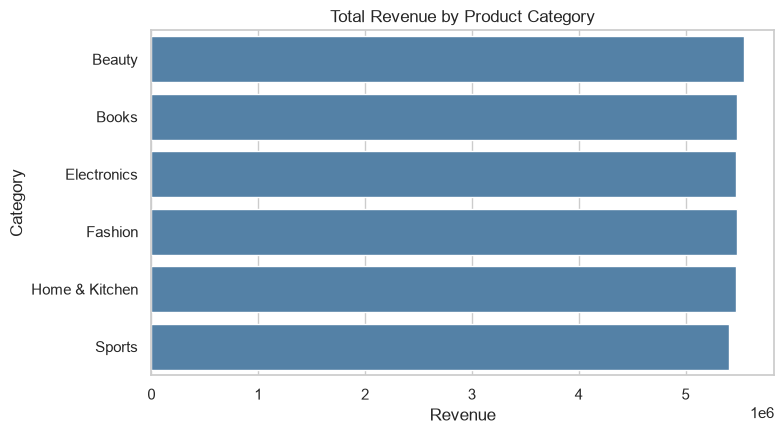

In [30]:
# Revenue by Category
cat_sorted = cat.sort_values("revenue", ascending=False)

plt.figure(figsize=(8, 4.5))
sns.barplot(data=cat_sorted, y="product_category", x="revenue", color="steelblue")

plt.title("Total Revenue by Product Category")
plt.xlabel("Revenue")
plt.ylabel("Category")
plt.tight_layout()

plt.show()

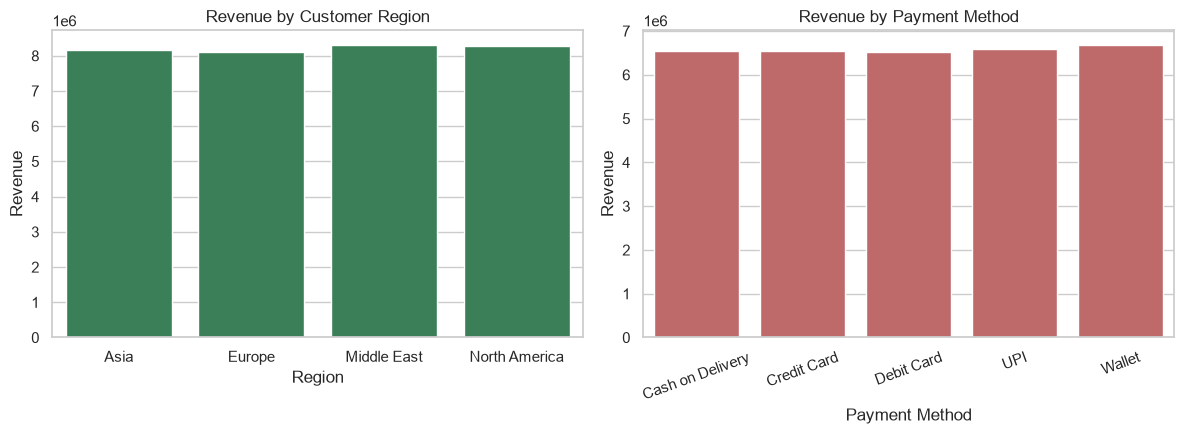

In [32]:
# Revenue by Region and Payment Method

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
sns.barplot(data=reg.reset_index(), x="customer_region", y="revenue", color="seagreen")
plt.title("Revenue by Customer Region")
plt.xlabel("Region")
plt.ylabel("Revenue")


plt.subplot(1, 2, 2)
sns.barplot(data=pay.reset_index(), x="payment_method", y="revenue", color="indianred")
plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

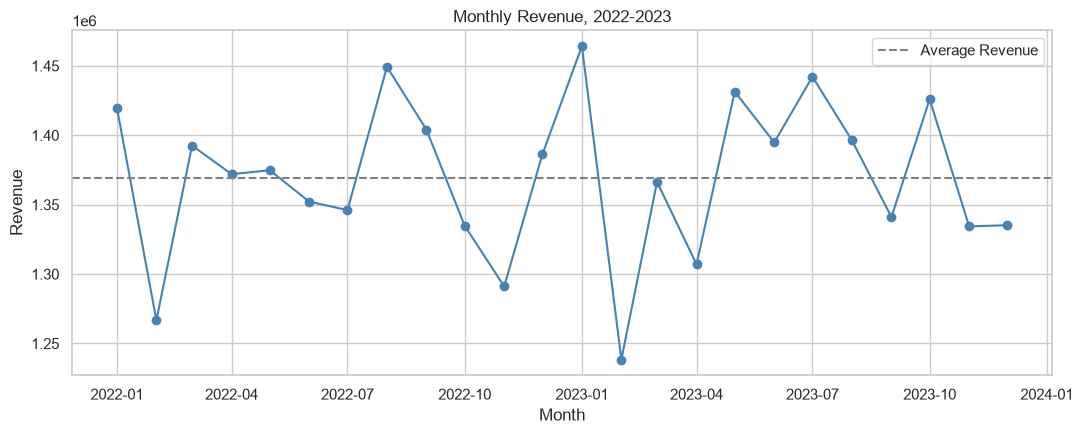

In [33]:
# Monthly Revenue Trend

monthly = df.groupby("year_month")["total_revenue"].sum()

plt.figure(figsize=(11, 4.5))

plt.plot(monthly.index, monthly.values, marker="o", color="steelblue")

plt.axhline(monthly.mean(), color="grey", linestyle="--",
            label="Average Revenue")

plt.title("Monthly Revenue, 2022-2023")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.legend()

plt.tight_layout()
plt.show()

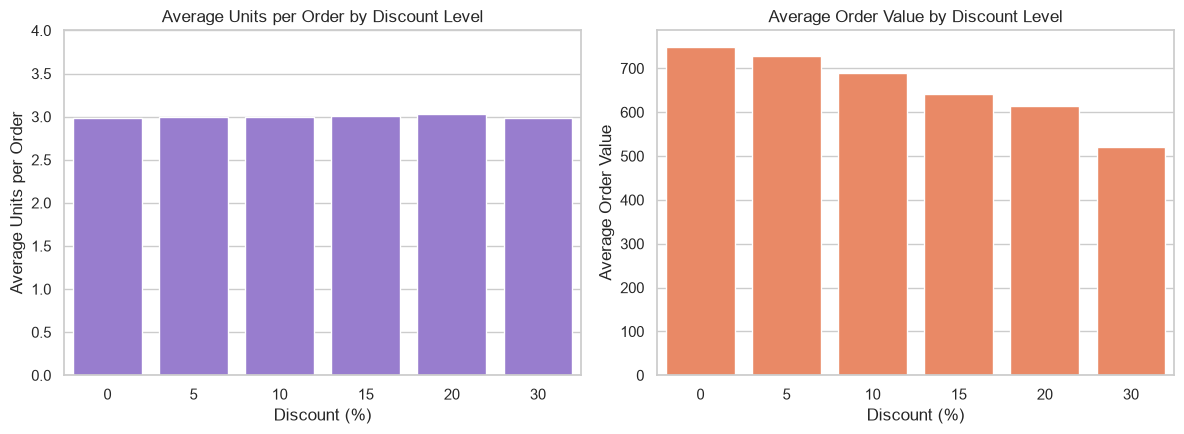

In [34]:
# Discount Level vs Units Sold and Average Order Value

plt.figure(figsize=(12, 4.5))
plt.subplot(1, 2, 1)
sns.barplot(data=df, x="discount_percent", y="quantity_sold",
            color="mediumpurple", errorbar=None)

plt.title("Average Units per Order by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Average Units per Order")
plt.ylim(0, 4)

plt.subplot(1, 2, 2)
sns.barplot(data=df, x="discount_percent", y="total_revenue",
            color="coral", errorbar=None)

plt.title("Average Order Value by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Average Order Value")

plt.tight_layout()
plt.show()

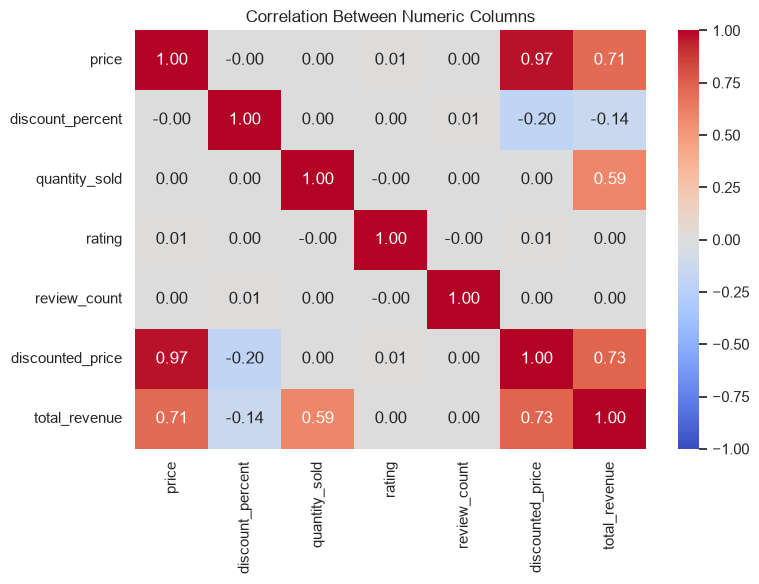

In [36]:
# Chart 5: Correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f", ax=ax)
ax.set_title("Correlation Between Numeric Columns")
plt.tight_layout()
plt.show()

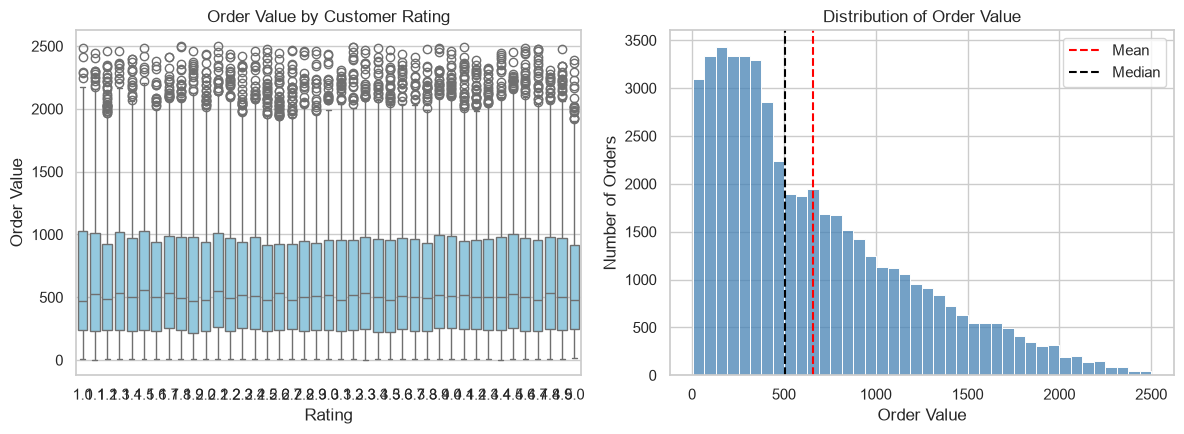

In [37]:
# Rating vs Revenue and Order Value Distribution

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x="rating", y="total_revenue", color="skyblue")

plt.title("Order Value by Customer Rating")
plt.xlabel("Rating")
plt.ylabel("Order Value")

plt.subplot(1, 2, 2)
sns.histplot(df["total_revenue"], bins=40, color="steelblue")

plt.axvline(df["total_revenue"].mean(), color="red",
            linestyle="--", label="Mean")
plt.axvline(df["total_revenue"].median(), color="black",
            linestyle="--", label="Median")

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.legend()

plt.tight_layout()
plt.show()

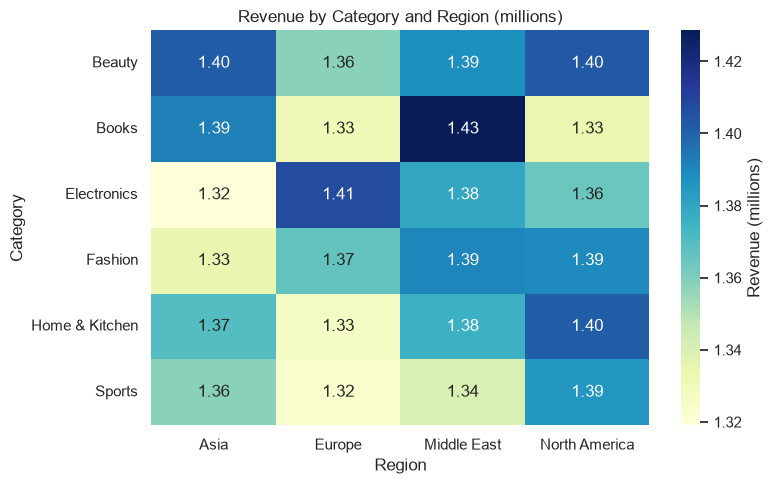

In [38]:
# Chart 7: Category x region heatmap of revenue
pivot = df.pivot_table(index="product_category", columns="customer_region", values="total_revenue",
                       aggfunc="sum", observed=True) / 1e6
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "Revenue (millions)"})
ax.set_title("Revenue by Category and Region (millions)")
ax.set_xlabel("Region"); ax.set_ylabel("Category")
plt.tight_layout()
plt.show()

## 6. Insights and Conclusion

In [40]:


# 1. Best and Worst Product Categories
best_cat = cat["revenue"].idxmax()
worst_cat = cat["revenue"].idxmin()

print("1. Category Revenue")
print("Best:", best_cat, cat["revenue"].max())
print("Worst:", worst_cat, cat["revenue"].min())


# 2. Average Units Sold by Discount
print("\n2. Average Units Sold")
print("0% Discount:", disc.loc[0, "avg_units"])
print("30% Discount:", disc.loc[30, "avg_units"])


# 3. Average Order Value by Discount
print("\n3. Average Order Value")
print("0% Discount:", disc.loc[0, "avg_order_value"])
print("30% Discount:", disc.loc[30, "avg_order_value"])


# 4. Correlation with Revenue
print("\n4. Correlation with Revenue")
print(corr["total_revenue"])


# 5. Revenue Growth from 2022 to 2023
growth = (yearly[2023] / yearly[2022] - 1) * 100
print("\n5. Revenue Growth:", round(growth, 2), "%")


# 6. Best and Worst Weekdays
print("\n6. Weekday Revenue")
print("Best:", wk.idxmax(), wk.max())
print("Worst:", wk.idxmin(), wk.min())


# 7. Discount Analysis
disc_share = (df["discount_percent"] > 0).mean() * 100

lost = (df["price"] * df["quantity_sold"] - df["total_revenue"]).sum()

print("\n7. Discount Analysis")
print("Orders with Discounts:", round(disc_share, 2), "%")
print("Revenue Lost Through Discounts:", round(lost, 2))

1. Category Revenue
Best: Beauty 5550624.97
Worst: Sports 5407235.82

2. Average Units Sold
0% Discount: 2.99
30% Discount: 2.98

3. Average Order Value
0% Discount: 749.03
30% Discount: 521.56

4. Correlation with Revenue
price               0.71
discount_percent   -0.14
quantity_sold       0.59
rating              0.00
review_count        0.00
discounted_price    0.73
total_revenue       1.00
Name: total_revenue, dtype: float64

5. Revenue Growth: 0.54 %

6. Weekday Revenue
Best: Friday 4880146.2
Worst: Monday 4614737.85

7. Discount Analysis
Orders with Discounts: 83.57 %
Revenue Lost Through Discounts: 5046530.8


### Key insights

1. **Discounts do not increase the number of units bought.** Orders have about 3 units on average at every discount level, from 0% to 30%. Customers are not buying more because the price is lower.
2. **That means discounts mostly cost money.** The average order at a 30% discount brings in about 30% less revenue than an order with no discount (around 522 vs 749). About 84% of orders carried some discount, and together they gave up roughly 13% of the list-price value of everything sold.
3. **Revenue comes from price and quantity, nothing else.** Price (correlation about 0.71) and quantity (about 0.59) explain revenue. Discount is weakly negative (about -0.14).
4. **Revenue is spread evenly across categories.** The best category (Beauty) leads the weakest (Sports) by only about 2.7%. There is no star category to push and no weak one to cut.
5. **Regions and payment methods are almost equal too.** The Middle East and North America are about 2% ahead of Asia and Europe, and Wallet is slightly ahead of UPI and Debit Card, but the differences are too small to act on.
6. **The business is flat over time.** 2023 revenue is only about 0.5% above 2022, and monthly revenue stays near 1.37M with no clear seasonal peak.
7. **Ratings and review counts have no link with sales.** Their correlation with revenue is about 0.00, and every rating from 1 to 5 shows the same order values.
8. **Fridays are the strongest day** for revenue (about 4.88M), about 6% above the Monday-to-Wednesday average (Monday is the weakest).

### Conclusion

On this data, the discount policy is the clear problem to look at. Deeper discounts did not make people buy more, and the average order shrinks as the discount grows. A sensible next step would be to test cutting the 20% and 30% offers (for example on a few categories or regions) and see whether volume really holds, since the data suggests it would and revenue per order would rise. Beyond that, no category, region or payment method needs special attention, because all of them perform almost identically.

